
--- Training Baseline U-Net ---
Total Parameters: 6,233,794
Inference Latency: 26.12 ms
Per-Class IoU -> Background: 0.4607 | Vessel: 0.1938 | mIoU: 0.3273

--- Training Dilated Bottleneck ---
Total Parameters: 6,233,794
Inference Latency: 26.89 ms
Per-Class IoU -> Background: 0.8656 | Vessel: 0.4372 | mIoU: 0.6514

Generating Visual Comparison Plot...


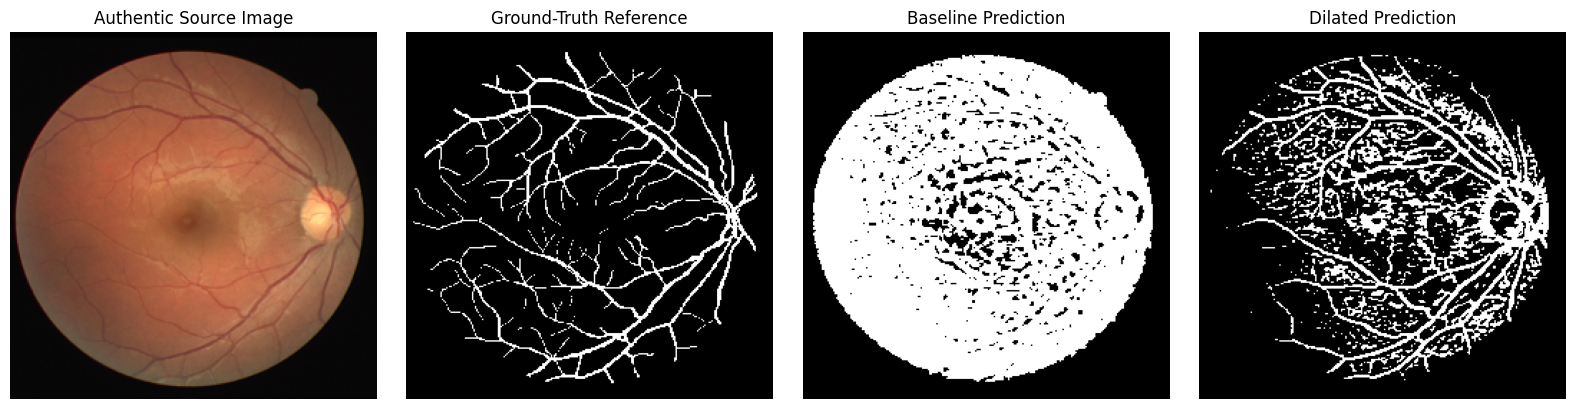

In [8]:
import os
import time
import glob
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader

# 1. Set Deterministic Seed
def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic = True
set_seed(42)

# 2. Data Contract & Loader (Using ONLY the fully labeled 'training' folder)
class DRIVEDataset(Dataset):
    def __init__(self, image_paths, is_train=True):
        self.image_paths = image_paths
        self.is_train = is_train

    def __len__(self): 
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        
        # Since we are exclusively using the training folder, ALL files have the '_training' suffix
        mask_path = img_path.replace('/images/', '/1st_manual/').replace('_training.tif', '_manual1.gif')
        fov_path = img_path.replace('/images/', '/mask/').replace('_training.tif', '_training_mask.gif')
            
        if not os.path.exists(mask_path):
            raise FileNotFoundError(f"Missing Mask: {mask_path}")
            
        # Use PIL to read files safely
        img = Image.open(img_path).convert('RGB').resize((256, 256), Image.BILINEAR)
        img = (np.array(img) / 255.0 - 0.5) / 0.5
        
        vessel = Image.open(mask_path).convert('L').resize((256, 256), Image.NEAREST)
        fov = Image.open(fov_path).convert('L').resize((256, 256), Image.NEAREST)
        
        vessel = np.array(vessel)
        fov = np.array(fov)
        
        # Label Contract: 1 (Vessel), 0 (Background), 255 (Ignored outside FOV)
        label = (vessel > 127).astype(np.int64)
        label[fov < 127] = 255 
        
        # Data Augmentation (Train only)
        if self.is_train and np.random.rand() > 0.5:
            img = np.fliplr(img).copy()
            label = np.fliplr(label).copy()

        return torch.tensor(img).permute(2,0,1).float(), torch.tensor(label).long()

# Find all 20 labeled images in the training folder dynamically
all_imgs = sorted(glob.glob('/kaggle/input/**/training/images/*.tif', recursive=True))

# Split the 20 labeled images: 16 for training, 4 for test evaluation
train_imgs = all_imgs[:16]
test_imgs = all_imgs[16:]

train_loader = DataLoader(DRIVEDataset(train_imgs, True), batch_size=4, shuffle=True)
test_loader = DataLoader(DRIVEDataset(test_imgs, False), batch_size=1, shuffle=False)

# 3. Baseline & Controlled Change Architecture
class UNetSegmenter(nn.Module):
    def __init__(self, use_dilation=False):
        super().__init__()
        self.enc1 = nn.Sequential(nn.Conv2d(3, 64, 3, padding=1), nn.ReLU(inplace=True))
        self.enc2 = nn.Sequential(nn.MaxPool2d(2), nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(inplace=True))
        self.enc3 = nn.Sequential(nn.MaxPool2d(2), nn.Conv2d(128, 256, 3, padding=1), nn.ReLU(inplace=True))
        
        if not use_dilation:
            self.bottleneck = nn.Sequential(
                nn.MaxPool2d(2),
                nn.Conv2d(256, 512, 3, padding=1), nn.ReLU(inplace=True),
                nn.Conv2d(512, 512, 3, padding=1), nn.ReLU(inplace=True)
            )
        else:
            self.bottleneck = nn.Sequential(
                nn.MaxPool2d(2),
                nn.Conv2d(256, 512, 3, padding=2, dilation=2), nn.ReLU(inplace=True), 
                nn.Conv2d(512, 512, 3, padding=4, dilation=4), nn.ReLU(inplace=True)  
            )
            
        self.up3 = nn.UpsamplingBilinear2d(scale_factor=2)
        self.dec3 = nn.Sequential(nn.Conv2d(512+256, 256, 3, padding=1), nn.ReLU(inplace=True))
        self.up2 = nn.UpsamplingBilinear2d(scale_factor=2)
        self.dec2 = nn.Sequential(nn.Conv2d(256+128, 128, 3, padding=1), nn.ReLU(inplace=True))
        self.up1 = nn.UpsamplingBilinear2d(scale_factor=2)
        self.dec1 = nn.Sequential(nn.Conv2d(128+64, 64, 3, padding=1), nn.ReLU(inplace=True))
        self.head = nn.Conv2d(64, 2, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        b = self.bottleneck(e3)
        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head(d1)

# 4. Training & Evaluation Engine
def train_and_eval(model_name, use_dilation):
    print(f"\n--- Training {model_name} ---")
    model = UNetSegmenter(use_dilation).cuda()
    
    # Bumped learning rate slightly to speed up convergence in just 30 epochs
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3)
    
    # THE FIX: Class weights. Penalize missing a vessel (index 1) 9x more than background (index 0).
    weights = torch.tensor([0.1, 0.9]).cuda()
    criterion = nn.CrossEntropyLoss(weight=weights, ignore_index=255) 
    
    scaler = torch.amp.GradScaler('cuda') 
    
    model.train()
    for epoch in range(30):
        for imgs, masks in train_loader:
            imgs, masks = imgs.cuda(), masks.cuda()
            optimizer.zero_grad()
            with torch.amp.autocast('cuda'):
                logits = model(imgs)
                loss = criterion(logits, masks)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

    params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Total Parameters: {params:,}")

    dummy_input = torch.randn(1, 3, 256, 256).cuda()
    model.eval()
    with torch.no_grad():
        for _ in range(20): model(dummy_input)
        torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(100): model(dummy_input)
        torch.cuda.synchronize()
        latency = (time.time() - t0) / 100.0 * 1000 
    print(f"Inference Latency: {latency:.2f} ms")

    cm = np.zeros((2, 2))
    for imgs, masks in test_loader:
        imgs, masks = imgs.cuda(), masks.cpu().numpy()
        with torch.no_grad():
            preds = torch.argmax(model(imgs), dim=1).cpu().numpy()
        
        valid = masks != 255
        for i in range(2):
            for j in range(2):
                cm[i, j] += np.sum((masks[valid] == i) & (preds[valid] == j))

    iou_bg = cm[0,0] / (cm[0,0] + cm[0,1] + cm[1,0])
    iou_vessel = cm[1,1] / (cm[1,1] + cm[1,0] + cm[0,1])
    miou = (iou_bg + iou_vessel) / 2
    print(f"Per-Class IoU -> Background: {iou_bg:.4f} | Vessel: {iou_vessel:.4f} | mIoU: {miou:.4f}")
    
    return model

baseline_model = train_and_eval("Baseline U-Net", False)
dilated_model = train_and_eval("Dilated Bottleneck", True)

# 5. Visual Evidence Plotter
def plot_comparison():
    print("\nGenerating Visual Comparison Plot...")
    baseline_model.eval()
    dilated_model.eval()
    
    imgs, masks = next(iter(test_loader))
    imgs, masks = imgs.cuda(), masks.cpu().numpy()
    
    with torch.no_grad():
        base_preds = torch.argmax(baseline_model(imgs), dim=1).cpu().numpy()
        dilated_preds = torch.argmax(dilated_model(imgs), dim=1).cpu().numpy()
        
    img_display = imgs[0].cpu().permute(1, 2, 0).numpy()
    img_display = (img_display * 0.5) + 0.5 
    
    mask_display = masks[0]
    mask_display[mask_display == 255] = 0 
    
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(img_display)
    axes[0].set_title("Authentic Source Image")
    axes[0].axis('off')
    
    axes[1].imshow(mask_display, cmap='gray')
    axes[1].set_title("Ground-Truth Reference")
    axes[1].axis('off')
    
    axes[2].imshow(base_preds[0], cmap='gray')
    axes[2].set_title("Baseline Prediction")
    axes[2].axis('off')
    
    axes[3].imshow(dilated_preds[0], cmap='gray')
    axes[3].set_title("Dilated Prediction")
    axes[3].axis('off')
    
    plt.tight_layout()
    plt.show()

plot_comparison()